# Public external data and eligibility

Read the included cycle-level extracts, verify their checksums and reproduce the
external eligibility counts. Instructions for downloading the original full-rate
records are in `data/external/SOURCES.md`.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:07:00+00:00
Inputs: included aggregate tables and public external extracts


## Verify public readers and derive the external cohorts

In [2]:
from extval import kfs,leap,ngl,cohort
kfs_cycles=kfs.read_cycles();leap_cycles=leap.read_cycles();payload=ngl.read_payload()
print("Embedded checksums passed:",len(kfs_cycles),"KFS tests;",len(leap_cycles),"LEAP tests;",
      sum(map(len,payload.values())),"NGL tests before filtering")
rows=[]
groups={"KFS-TCUI":kfs.records(series=("TCUI",),control_amplitude="nominal"),
        "KFS-TCUA":[r for r in kfs.records(series=("TCUA",),control_amplitude="nominal") if r["name"] not in cohort.EXTERNAL_EXCLUDE],
        "LEAP-2017":leap.records(control_amplitude="nominal")}
for name,recs in groups.items():
    keep=[r for r in recs if r["N"][-1]>10 and not (r["event"]["liq"] and r["event"]["n_liq"]<=10)]
    rows.append(dict(source=name,tests=len(keep),events=sum(r["event"]["liq"] for r in keep)))
for name in ["Adapazari","Christchurch"]:
    d=ngl.table(name)
    keep=d[d.qc_pass & d.rows.map(lambda x:x[-1,0]>10) & ~(d.sus3.between(0,10,inclusive="right"))]
    rows.append(dict(source=name,tests=len(keep),events=int((keep.sus3>0).sum())))
derived=pd.DataFrame(rows).set_index("source").sort_index()
expected=pd.read_csv(TABLES/"external_counts.csv").set_index("source").sort_index()
pd.testing.assert_frame_equal(derived,expected[["tests","events"]],check_dtype=False)
display(expected)
assert expected.tests.sum()==127 and expected.events.sum()==99 and expected.curve_tests.sum()==125
print("Eligibility reproduced from the public extracts.")

Embedded checksums passed: 40 KFS tests; 23 LEAP tests; 145 NGL tests before filtering


,tests,curve_tests,events,known_non_events,unresolved
source,,,,,
Adapazari,54,53,46,0,8
Christchurch,21,20,15,0,6
KFS-TCUA,14,14,1,0,13
KFS-TCUI,20,20,20,0,0
LEAP-2017,18,18,17,0,1


Eligibility reproduced from the public extracts.


## Pressure histories from public data

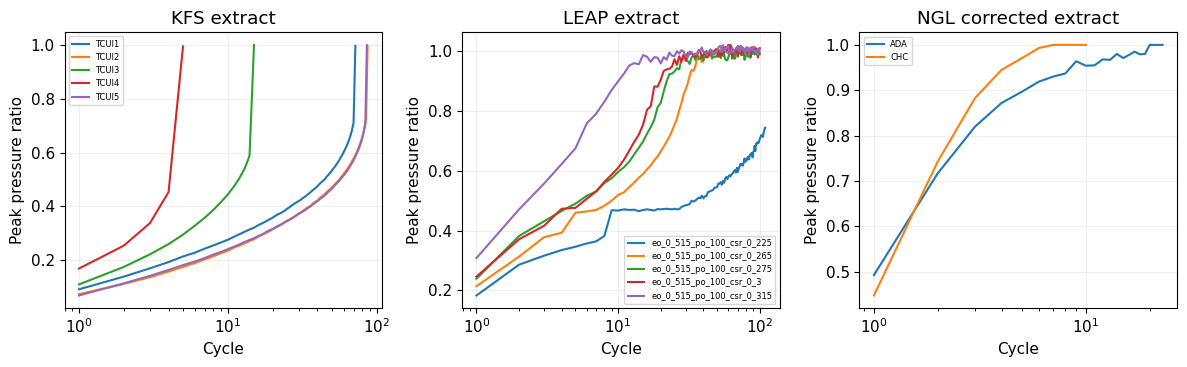

In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,3.8))
for name,d in list(kfs_cycles.items())[:5]:axes[0].plot(d.N,d.ru_max,label=name)
for name,(d,meta) in list(leap_cycles.items())[:5]:axes[1].plot(d.N,d.ru_max,label=name)
for tag,d in payload.items():
    row=d.iloc[0]["rows"]
    axes[2].plot(row[:,0],row[:,1]/1000,label=tag)
for ax,title in zip(axes,["KFS extract","LEAP extract","NGL corrected extract"]):
    ax.set(xlabel="Cycle",ylabel="Peak pressure ratio",title=title,xscale="log")
    ax.legend(fontsize=6)
fig.tight_layout();plt.show()

## Input mapping

The adapters retain source-specific pressure normalization and event rules from
the original-resolution records. Building the final NGL model inputs also requires
the mechanical-property imputers fitted on each internal training fold.